# C4: Categorical Data Considerations

## 1. Introduction to Categorical Data

Categorical data represents variables that contain label values rather than numeric values. The number of possible values is often limited to a fixed set. 

### Types of Categorical Data:
1. **Nominal Data**: Data with no intrinsic ordering (e.g., Color: Red, Blue, Green; City: New York, London, Paris).
2. **Ordinal Data**: Data with a clear ordering (e.g., Size: Small, Medium, Large; Rating: 1 to 5).

In this notebook, we will explore how to analyze, visualize, and preprocess categorical variables using a Flight Price dataset.

### Learning Objectives:
- Identify Nominal and Ordinal variables.
- Perform Exploratory Data Analysis (EDA) on categorical features.
- Visualize relationships between categorical features and target variables.
- Handle high cardinality and rare labels.
- Apply encoding techniques: One-Hot Encoding and Label/Ordinal Encoding.

![Categorical Data Types](https://oercollective.caul.edu.au/app/uploads/sites/58/2023/01/Figure_9.1-e1675206189966.jpg)
*Image Source: GeeksforGeeks*

---

## A Note on Dataset Change

In this notebook, we transition from the **Divorce Data Analysis** dataset (used in C1-C3) to the **Flight Price** dataset.

**Why the change?**
1. **Variety**: Real-world analysts work with different datasets regularly
2. **Richer categorical features**: Airlines, routes, and stops provide diverse categorical examples
3. **Business relevance**: Flight pricing is a common analytics use case

**Skills transfer**: The techniques you learn here (encoding, rare label handling) apply to ANY categorical data, including the education columns from the divorce dataset.

**Cross-reference**: Remember from **C2** - if you encounter missing values in categorical columns, use **Mode Imputation** (the most frequent category).

---

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Settings for better readability
pd.set_option('display.max_columns', None)
plt.style.use('ggplot')

# Load the dataset
try:
    df = pd.read_csv('../../00-data/EDA Search Results.csv')
    print("Dataset loaded successfully!")
except FileNotFoundError:
    print("Error: File not found. Please check the path.")

# Display first few rows
df.head()

Dataset loaded successfully!


,Airline,Date_of_Journey,Source,Destination,Route,Dep_Time,Arrival_Time,Duration,Total_Stops,Additional_Info,Price
0,Jet Airways,9/06/2019,Delhi,Cochin,DEL → LKO → BOM → COK,09:25,04:25 10 Jun,19h,2 stops,No info,13882.0
1,IndiGo,12/05/2019,Kolkata,Banglore,CCU → NAG → BLR,18:05,23:30,5h 25m,1 stop,No info,6218.0
2,IndiGo,01/03/2019,Banglore,New Delhi,BLR → NAG → DEL,16:50,21:35,4h 45m,1 stop,No info,13302.0
3,SpiceJet,24/06/2019,Kolkata,Banglore,CCU → BLR,09:00,11:25,2h 25m,non-stop,No info,3873.0
4,Jet Airways,12/03/2019,Banglore,New Delhi,BLR → BOM → DEL,18:55,10:25 13 Mar,15h 30m,1 stop,In-flight meal not included,11087.0


## 2. Basic Inspection

Let's identify the categorical variables in our dataset. Usually, columns with `object` dtype are categorical.

In [2]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10660 entries, 0 to 10659
Data columns (total 11 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   Airline          10233 non-null  object 
 1   Date_of_Journey  10338 non-null  object 
 2   Source           10473 non-null  object 
 3   Destination      10313 non-null  object 
 4   Route            10404 non-null  object 
 5   Dep_Time         10400 non-null  object 
 6   Arrival_Time     10466 non-null  object 
 7   Duration         10446 non-null  object 
 8   Total_Stops      10448 non-null  object 
 9   Additional_Info  10071 non-null  object 
 10  Price            10044 non-null  float64
dtypes: float64(1), object(10)
memory usage: 916.2+ KB


**Observations:**
- **Categorical Features**: `Airline`, `Date_of_Journey`, `Source`, `Destination`, `Route`, `Dep_Time`, `Arrival_Time`, `Duration`, `Total_Stops`, `Additional_Info`.
- **Target Variable**: `Price` (Numerical).

*> Note: Some features like `Date_of_Journey`, `Dep_Time`, `Arrival_Time` are technically temporal but currently read as objects. We will focus on the string-based categorical/nominal/ordinal features here.*

## 3. Exploratory Data Analysis (EDA) for Categorical Data

For categorical variables, we typically look at:
1. **Cardinality**: How many unique labels are there?
2. **Frequency**: How often does each label occur? (`value_counts`)
3. **Relationship with Target**: How does the category affect the Price?

### 3.1 Analyzing Cardinality and Frequency

In [3]:
# List of categorical columns to analyze
cat_cols = ['Airline', 'Source', 'Destination', 'Total_Stops', 'Additional_Info']

for col in cat_cols:
    print(f"\n--- {col} ---")
    print(f"Unique Values: {df[col].nunique()}")
    print(df[col].value_counts())


--- Airline ---
Unique Values: 8
Airline
Jet Airways          3685
IndiGo               1981
Air India            1686
Multiple carriers    1148
SpiceJet              787
Vistara               455
Air Asia              309
GoAir                 182
Name: count, dtype: int64

--- Source ---
Unique Values: 5
Source
Delhi       4451
Kolkata     2814
Banglore    2149
Mumbai       685
Chennai      374
Name: count, dtype: int64

--- Destination ---
Unique Values: 6
Destination
Cochin       4391
Banglore     2773
Delhi        1219
New Delhi     888
Hyderabad     673
Kolkata       369
Name: count, dtype: int64

--- Total_Stops ---
Unique Values: 5
Total_Stops
1 stop      5503
non-stop    3411
2 stops     1488
3 stops       45
4 stops        1
Name: count, dtype: int64

--- Additional_Info ---
Unique Values: 10
Additional_Info
No info                         7867
In-flight meal not included     1874
No check-in baggage included     299
1 Long layover                    18
Change airports      

### 3.2 Visualizing Categorical Distributions

Visualizing the count of each category helps us identify dominant categories and potential rare labels.

/var/folders/pz/82_6wg3s3jngvml3zjpsjgdh0000gn/T/ipykernel_22399/1405057955.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, y=col, order=df[col].value_counts().index, palette='viridis')
/var/folders/pz/82_6wg3s3jngvml3zjpsjgdh0000gn/T/ipykernel_22399/1405057955.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, y=col, order=df[col].value_counts().index, palette='viridis')
/var/folders/pz/82_6wg3s3jngvml3zjpsjgdh0000gn/T/ipykernel_22399/1405057955.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, y=col,

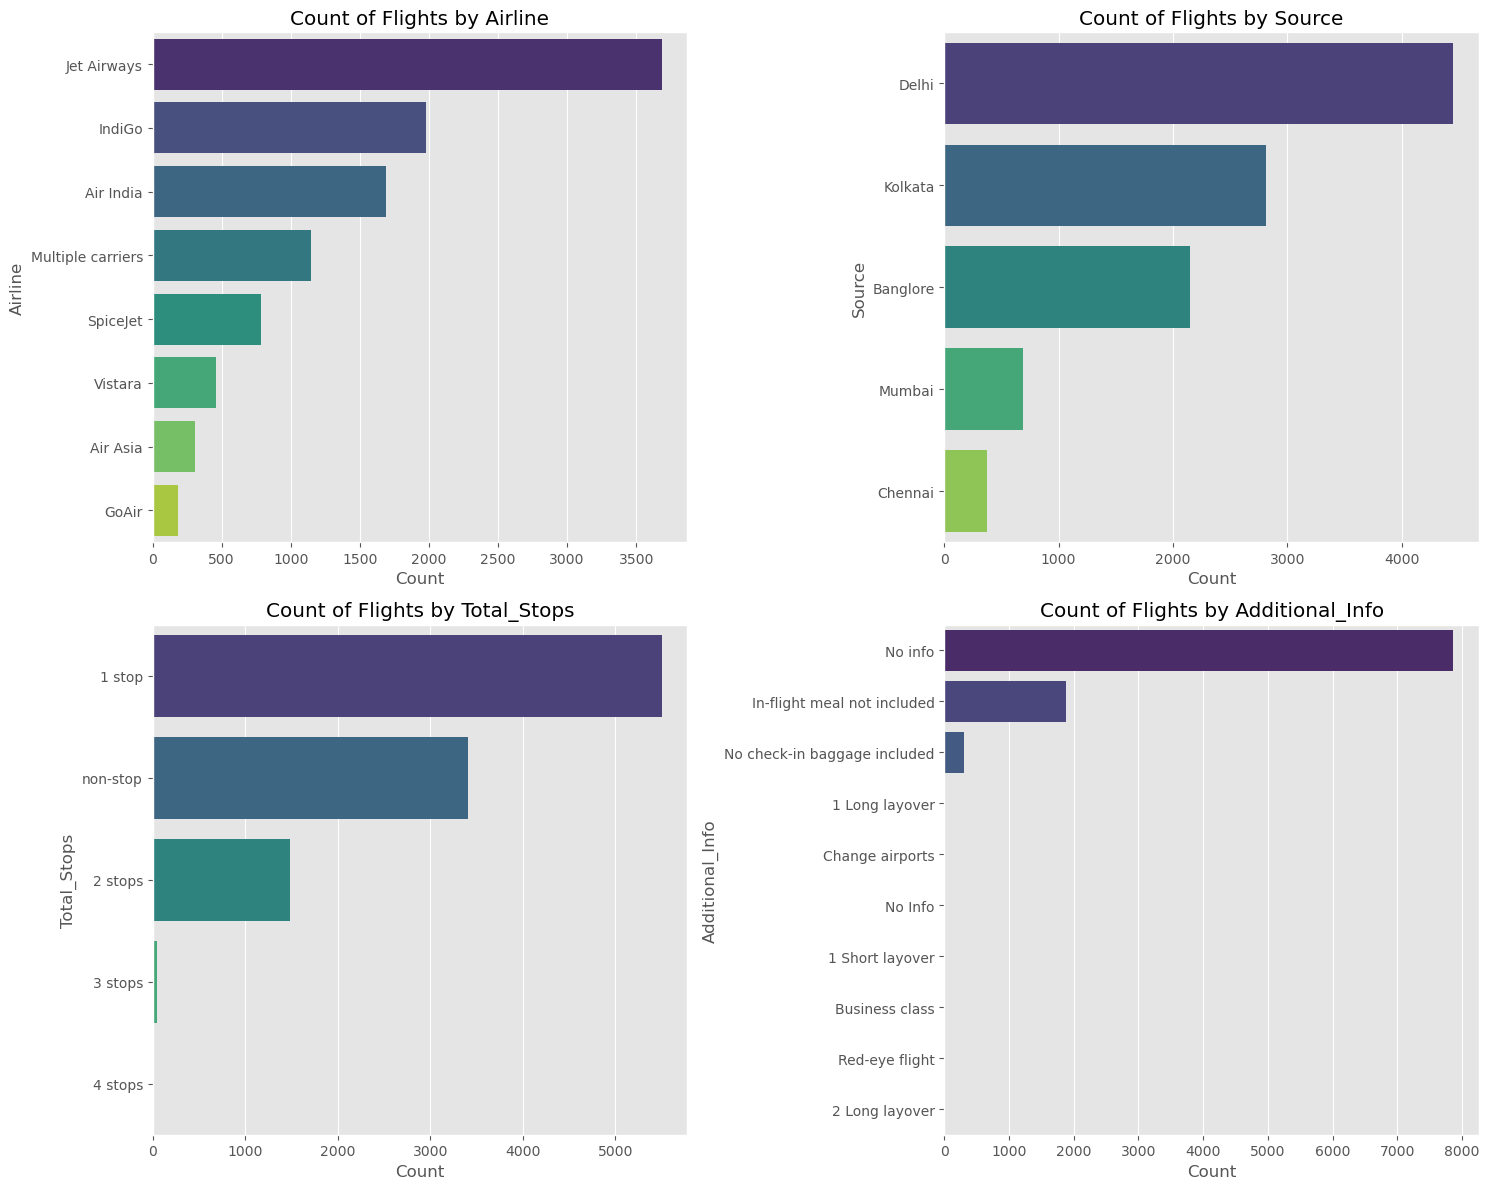

In [4]:
plt.figure(figsize=(15, 12))

# Plotting countplots for selected categorical features
for i, col in enumerate(['Airline', 'Source', 'Total_Stops', 'Additional_Info']):
    plt.subplot(2, 2, i + 1)
    sns.countplot(data=df, y=col, order=df[col].value_counts().index, palette='viridis')
    plt.title(f'Count of Flights by {col}')
    plt.xlabel('Count')
    plt.ylabel(col)

plt.tight_layout()
plt.show()

### 3.3 Categorical vs. Target (Price)

Using Boxplots or Violinplots, we can see how the price distribution varies across different categories. This is crucial for determining if a categorical feature is a good predictor.

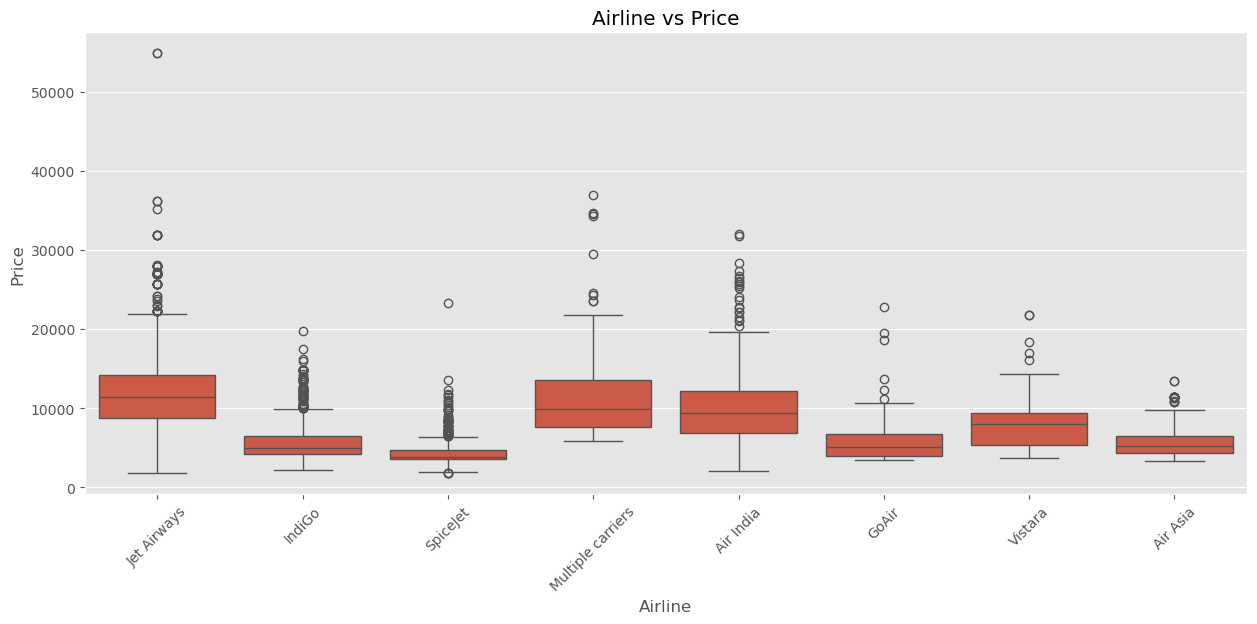

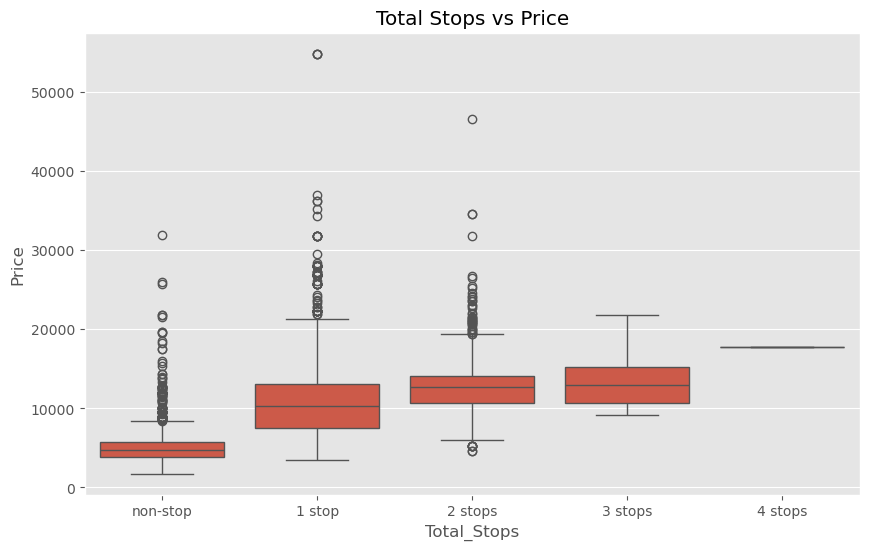

In [5]:
plt.figure(figsize=(15, 6))
sns.boxplot(x='Airline', y='Price', data=df)
plt.title('Airline vs Price')
plt.xticks(rotation=45)
plt.show()

plt.figure(figsize=(10, 6))
sns.boxplot(x='Total_Stops', y='Price', data=df, order=['non-stop', '1 stop', '2 stops', '3 stops', '4 stops'])
plt.title('Total Stops vs Price')
plt.show()

**Insight from Plots:**
- **Airline**: `Jet Airways Business` has a significantly higher price range compared to others. Low-cost carriers like `SpiceJet` have lower median prices.
- **Total_Stops**: There is a clear trend where more stops generally correlate with higher prices (likely due to longer duration/distance or multi-leg costs).

## 4. Handling Rare Labels

**Problem**: High cardinality (many unique categories) can lead to overfitting, especially if some categories have very few observations (Rare Labels).
**Solution**: Group rare labels into a new category called "Other".

Let's check `Additional_Info`.

In [6]:
print(df['Additional_Info'].value_counts())

# Calculate percentage of each category
label_freq = df['Additional_Info'].value_counts() / len(df)
print("\n--- Frequencies ---")
print(label_freq)

Additional_Info
No info                         7867
In-flight meal not included     1874
No check-in baggage included     299
1 Long layover                    18
Change airports                    7
No Info                            2
1 Short layover                    1
Business class                     1
Red-eye flight                     1
2 Long layover                     1
Name: count, dtype: int64

--- Frequencies ---
Additional_Info
No info                         0.737992
In-flight meal not included     0.175797
No check-in baggage included    0.028049
1 Long layover                  0.001689
Change airports                 0.000657
No Info                         0.000188
1 Short layover                 0.000094
Business class                  0.000094
Red-eye flight                  0.000094
2 Long layover                  0.000094
Name: count, dtype: float64


We see categories like `1 Long layover`, `Change airports`, etc., that appear very infrequently (e.g., < 1% of data). Let's group anything below a 5% threshold into 'Other'.

In [7]:
threshold = 0.05
rare_labels = label_freq[label_freq < threshold].index

print(f"Rare labels to be grouped: {list(rare_labels)}")

# Create a copy to avoid SettingWithCopyWarning on original dataframe
df_processed = df.copy()

df_processed['Additional_Info'] = df_processed['Additional_Info'].apply(lambda x: 'Other' if x in rare_labels else x)

print("\nNew Value Counts:")
print(df_processed['Additional_Info'].value_counts())

Rare labels to be grouped: ['No check-in baggage included', '1 Long layover', 'Change airports', 'No Info', '1 Short layover', 'Business class', 'Red-eye flight', '2 Long layover']

New Value Counts:
Additional_Info
No info                        7867
In-flight meal not included    1874
Other                           330
Name: count, dtype: int64


## 5. Encoding Categorical Data

Machine Learning models generally require numerical input. We need to encode categorical string values into numbers.

### 5.1 Nominal Encoding (One-Hot Encoding)

Use this for nominal variables where no order exists (e.g., `Source`, `Airline`).

- **Technique**: Create a binary column for each category.
- **Function**: `pd.get_dummies()`
- **Note**: To avoid the "Dummy Variable Trap" (multicollinearity), we often drop the first category (`drop_first=True`).

In [8]:
# Example: One-Hot Encoding for 'Source'
source_dummies = pd.get_dummies(df[['Source']], drop_first=True)
source_dummies.head()

,Source_Chennai,Source_Delhi,Source_Kolkata,Source_Mumbai
0,False,True,False,False
1,False,False,True,False
2,False,False,False,False
3,False,False,True,False
4,False,False,False,False


### 5.2 Ordinal Encoding (Label Encoding)

Use this for ordinal variables where order matters (e.g., `Total_Stops`).

**Logic for `Total_Stops`**:
- non-stop -> 0
- 1 stop -> 1
- 2 stops -> 2
- 3 stops -> 3
- 4 stops -> 4

We can use a manual mapping dictionary for precise control.

In [9]:
# Check unique values first
print(df['Total_Stops'].unique())

# Define mapping
stops_mapping = {
    'non-stop': 0,
    '1 stop': 1,
    '2 stops': 2,
    '3 stops': 3,
    '4 stops': 4
}

# Apply mapping
df_processed['Total_Stops_Encoded'] = df_processed['Total_Stops'].map(stops_mapping)

# Check for NaN values (in case of unexpected categories)
print("NaN values after encoding:", df_processed['Total_Stops_Encoded'].isna().sum())

# Fill NaN if any (e.g. if 'nan' string exists, treat as 1 stop or drop)
# For this dataset, let's assume mode imputation if needed or drop.

df_processed[['Total_Stops', 'Total_Stops_Encoded']].head()

['2 stops' '1 stop' 'non-stop' nan '3 stops' '4 stops']
NaN values after encoding: 212


,Total_Stops,Total_Stops_Encoded
0,2 stops,2.0
1,1 stop,1.0
2,1 stop,1.0
3,non-stop,0.0
4,1 stop,1.0


### Resolving NaN Values After Encoding

We have 212 NaN values created during encoding. This happens when the original data had missing values (NaN). Let's handle these using **Mode Imputation** (as we learned in C2).

In [ ]:
# Handle NaN values with Mode Imputation
print(f"NaN values in Total_Stops_Encoded before fix: {df_processed['Total_Stops_Encoded'].isna().sum()}")

# Get mode (most common value) of the encoded column
mode_stops = df_processed['Total_Stops_Encoded'].mode()[0]
print(f"Mode value: {mode_stops} (corresponds to '1 stop')")

# Fill NaN with mode
df_processed['Total_Stops_Encoded'] = df_processed['Total_Stops_Encoded'].fillna(mode_stops)

print(f"NaN values after fix: {df_processed['Total_Stops_Encoded'].isna().sum()}")

# Verify the encoding distribution
print("\nEncoded value distribution:")
print(df_processed['Total_Stops_Encoded'].value_counts().sort_index())

### 5.3 Target Encoding (Mean Encoding)

For high-cardinality categorical features, One-Hot Encoding creates too many columns. **Target Encoding** replaces categories with the mean of the target variable.

**Use case**: When `Airline` has many categories and we want a single numerical column.

**Caution**: Can cause overfitting if not done carefully (use cross-validation in production).

In [ ]:
# Target Encoding: Replace each airline with its average price
target_means = df.groupby('Airline')['Price'].mean().sort_values(ascending=False)
print("Mean Price by Airline:")
print(target_means.round(2))

# Apply target encoding
df_processed['Airline_Target_Encoded'] = df_processed['Airline'].map(target_means)

# Visualize
plt.figure(figsize=(12, 5))
sns.barplot(x=target_means.index, y=target_means.values, palette='coolwarm')
plt.xticks(rotation=45)
plt.title('Target Encoding: Mean Price by Airline')
plt.ylabel('Mean Price')
plt.tight_layout()
plt.show()

# Show the encoded result
print("\nSample of encoded data:")
df_processed[['Airline', 'Airline_Target_Encoded', 'Price']].head(10)

### When to Use Each Encoding:

| Encoding Type | Best For | Pros | Cons |
|---------------|----------|------|------|
| **One-Hot** | Low cardinality (<10 categories), Nominal data | No information loss, Works with all models | High dimensionality |
| **Label/Ordinal** | Ordinal data with clear order | Single column, Preserves order | Implies false ordinality if misused |
| **Target** | High cardinality, Tree-based models | Single column, Captures target relationship | Risk of overfitting, Data leakage if not careful |

## 6. Exercises

**Exercise 1: Analyze `Destination`**
1. Plot the frequency of flights to each `Destination`.
2. Plot a boxplot of `Price` vs `Destination`.
3. Are there any rare labels in `Destination` (less than 5%)? If so, print them.

In [10]:
# Your Code Here

# 1. Countplot

# 2. Boxplot

# 3. Check for rare labels

**Exercise 2: Encode `Airline`**
1. `Airline` is a Nominal variable. Perform One-Hot Encoding on the `Airline` column.
2. Ensure you drop the first category to avoid dummy variable trap.
3. Concatenate the new columns with the main dataframe and display the first 5 rows.

In [11]:
# Your Code Here


**Exercise 3: Cross-Notebook Integration**
Return to the **Divorce Dataset** (from C1-C3) and apply what you learned:
1. Load `Divorce Data Analysis.csv`
2. Identify which columns are Nominal vs Ordinal (hint: `education_man`, `education_woman`)
3. Apply appropriate encoding to the education columns
4. If education levels have a natural order (e.g., Primary < Secondary < Professional), use ordinal encoding

**Bonus**: Create a correlation heatmap including the encoded education variables with `income_man` and `income_woman`.

In [ ]:
# Your Code Here

**Exercise 4: Handling High Cardinality**
The `Route` column has many unique values:
1. Calculate how many unique routes exist in the dataset
2. Apply the rare label grouping technique (threshold = 1%) to create an 'Other' category
3. How many routes remain after grouping?
4. Apply One-Hot Encoding to the simplified Route column - how many columns does this create?

**Reflection question**: When would you choose Target Encoding over One-Hot Encoding for the Route column?

In [ ]:
# Your Code Here

## Summary

- Categorical data can be Nominal or Ordinal.
- EDA helps identifying variable distribution and relationship with target.
- Rare labels should be handled to reduce feature space dimensionality.
- **One-Hot Encoding** is standard for Nominal data.
- **Label/Ordinal Encoding** is best for Ordinal data (preserves order).